<a href="https://colab.research.google.com/github/yoloaryan/ML/blob/main/ML_practcial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import Library

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

Creating the dataset


In [ ]:
data = {
    'CustomerID': range(1, 21),
    'Annual_Income': [15, 16, 17, 18, 25, 28, 30, 40, 42, 45, 50, 55, 60, 70, 75, 80, 85, 90, 95, 100],
    'Spending_Score': [39, 81, 6, 77, 40, 76, 6, 94, 3, 72, 50, 52, 48, 88, 12, 91, 15, 85, 10, 95]
}

In [ ]:
df=pd.DataFrame(data)

In [ ]:
df.head()

,CustomerID,Annual_Income,Spending_Score
0,1,15,39
1,2,16,81
2,3,17,6
3,4,18,77
4,5,25,40


# Select the required features

In [ ]:
X = df[['Annual_Income', 'Spending_Score']]

# c. Apply StandardScaler to standardize the data

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


Use the Elbow Method to determine the appropriate number of clusters

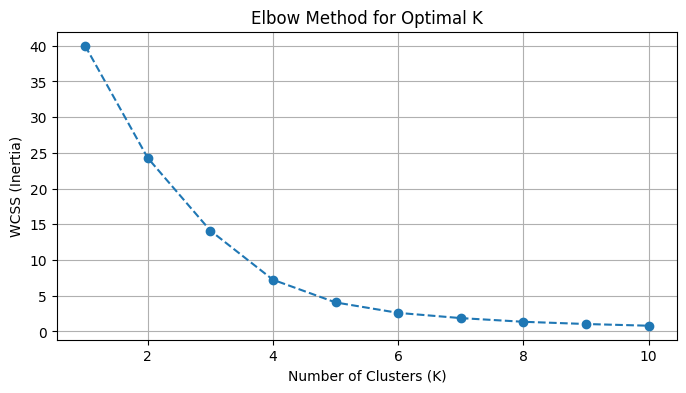

In [ ]:
wcss = []
for k in range(1, 11):
    kmeans_test = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans_test.fit(X_scaled)
    wcss.append(kmeans_test.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.grid(True)
plt.show()

# Apply K-means with K = 3

In [ ]:
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# Inverse transform centroids back to original scale for plotting & interpretation

In [ ]:

centroids_original = scaler.inverse_transform(kmeans.cluster_centers_)

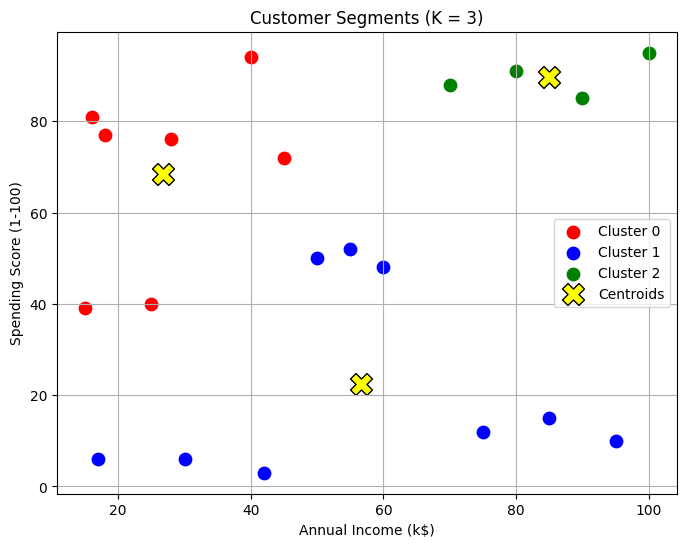

In [ ]:
plt.figure(figsize=(8, 6))
colors = ['red', 'blue', 'green']
for i in range(3):
    cluster_data = df[df['Cluster'] == i]
    plt.scatter(cluster_data['Annual_Income'], cluster_data['Spending_Score'],
                s=80, c=colors[i], label=f'Cluster {i}')

plt.scatter(centroids_original[:, 0], centroids_original[:, 1],
            s=250, c='yellow', marker='X', edgecolors='black', label='Centroids')

plt.title('Customer Segments (K = 3)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.grid(True)
plt.show()

# Q6. Employee Attrition Prediction using Random Forest

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# a. Load or create an employee dataset

In [ ]:
# Create sample employee dataset
employee_data = {
    'Age': [30, 40, 25, 35, 45, 22, 50, 32, 28, 41],
    'Department': ['Sales', 'HR', 'R&D', 'Sales', 'R&D', 'HR', 'R&D', 'Sales', 'R&D', 'Sales'],
    'OverTime': ['Yes', 'No', 'No', 'Yes', 'No', 'Yes', 'No', 'No', 'Yes', 'No'],
    'Attrition': ['Yes', 'No', 'No', 'Yes', 'No', 'Yes', 'No', 'No', 'No', 'No']
}
df = pd.DataFrame(employee_data)

# Encode categorical columns
le = LabelEncoder()
categorical_cols = ['Department', 'OverTime', 'Attrition']
for col in categorical_cols:
    df[col] = le.fit_transform(df[col])

# b. Encode categorical variables using LabelEncoder

In [ ]:
le = LabelEncoder()
categorical_cols = ['Department', 'OverTime', 'Attrition']
for col in categorical_cols:
    df[col] = le.fit_transform(df[col])


# c. Separate features and target variable

In [ ]:
X = df.drop('Attrition', axis=1)
y = df['Attrition']

# d. Split the dataset into training and testing sets (80% train, 20% test)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# e. Build a Random Forest Classifier

In [ ]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

# Predict on test set

In [ ]:
y_pred = rf_model.predict(X_test)

# f. Evaluate the model using Accuracy Score and Confusion Matrix

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print(f"Accuracy Score: {accuracy * 100:.2f}%")
print("\nConfusion Matrix:")
print(conf_matrix)

Accuracy Score: 50.00%

Confusion Matrix:
[[1 1]
 [0 0]]


# g. Display feature importance

In [ ]:
feature_importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\nFeature Importance:")
print(feature_importances)


Feature Importance:
      Feature  Importance
2    OverTime    0.482080
0         Age    0.347019
1  Department    0.170900


/tmp/ipykernel_1138/3892766608.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importances, palette='viridis')


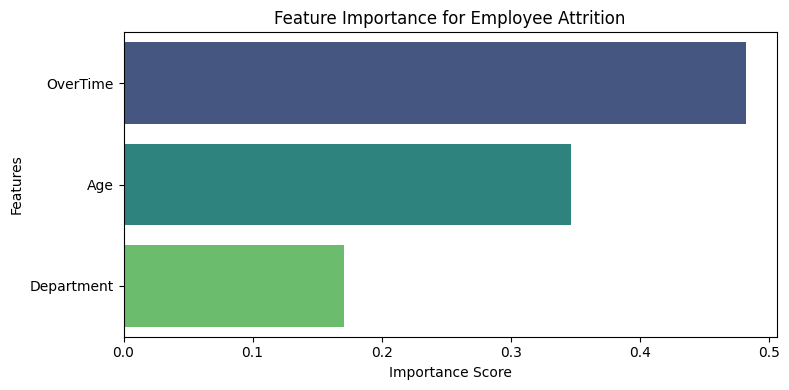

In [ ]:
plt.figure(figsize=(8, 4))
sns.barplot(x='Importance', y='Feature', data=feature_importances, palette='viridis')
plt.title('Feature Importance for Employee Attrition')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()